# Plotting time evolution of total parameter value

Plot the total energy (and CR component of them) for all models



In [1]:
import numpy as np
import os
import astropy.units as u
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import matplotlib.cm as cm
import matplotlib.colors as mcolors
from mpl_toolkits.axes_grid1 import make_axes_locatable
import matplotlib.ticker as ticker

import h5py
import json

from field_config import field_labels, field_lims, field_scales

In [2]:
bowshock_config_dict = json.load(open("../config/bowshock_config.json"))
bowshock_config = bowshock_config_dict["config"]
shock_labels = bowshock_config_dict["shock_labels"]

output_dir = "/home/kwatanabe/Projects/cr-bowshocks/updated_outputs"
fig_dir = "/home/kwatanabe/Projects/cr-bowshocks/figures/crmhd_vs_mhd"

### Plotting the total energy vs time

For the total energy & CR energy, we read this directly off from the starISM.dat and the CRsource.dat file/

In [3]:
def read_datfiles(fname, cr_fname=None):
    """Read the dat file from the starISM.dat file for each model."""
    data = np.genfromtxt(fname, skip_header=1)

    # the data has the order:
    # time, mass, x-mom, y-mom, z-mom, E_tot, E_kin, E_int, E_mag
    
    # first get time, and sort everything by time
    time_argsorted = np.argsort(data[:, 0])
    # convert to a dictionary
    data_dict = {
        "time": data[time_argsorted, 0] * u.s,
        "mass": data[time_argsorted, 1] * u.g,
        "x-mom": data[time_argsorted, 2] * u.g * u.cm /u.s,
        "y-mom": data[time_argsorted, 3] * u.g * u.cm /u.s,
        "z-mom": data[time_argsorted, 4] * u.g * u.cm /u.s,
        "E_tot": data[time_argsorted, 5] * u.erg,
        "E_kin": data[time_argsorted, 6] * u.erg,
        "E_int": data[time_argsorted, 7] * u.erg,
        "E_mag": data[time_argsorted, 8] * u.erg
    }

    if cr_fname is not None:
        # then read from the CRsources.dat to get the E_cr
        cr_data = np.genfromtxt(cr_fname, skip_header=1)

        # the data has the order:
        # time, dt, E_cr, dEcr_tot, dEcr_tot / dt
        time_argsorted = np.argsort(cr_data[:, 0])
        cr_data_dict = {
            "time" : cr_data[time_argsorted, 0] * u.s,
            "E_cr" : cr_data[time_argsorted, 2] * u.erg
        }

        # we can also add others but we don't need them for now
        
    else: # otherwise no CRs so set to zero
        cr_data_dict = {
            "time": data_dict["time"],
            "E_cr": np.zeros_like(data_dict["time"].value) * u.erg
        }
    return data_dict, cr_data_dict

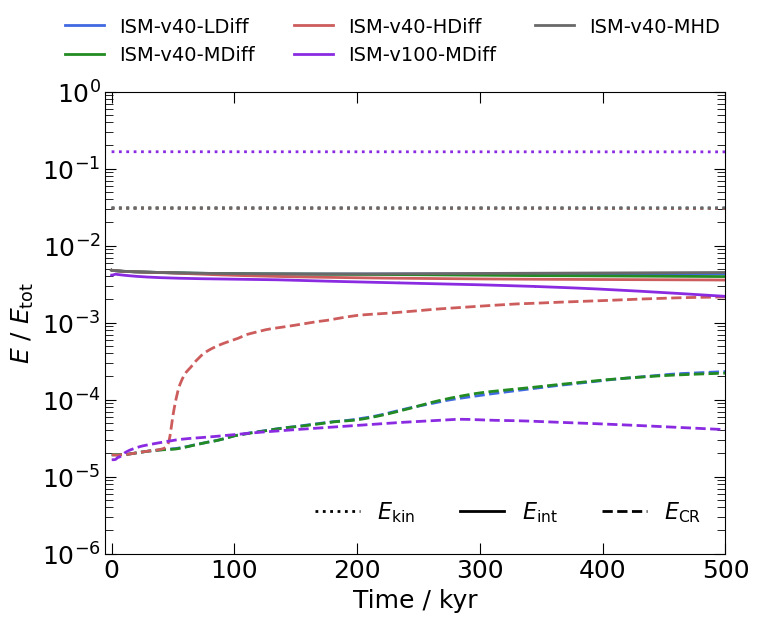

In [15]:
fig, ax = plt.subplots(figsize=(8,6))
sim_handles = []

for sim in list(bowshock_config.keys()):
    path_to_files = os.path.join(output_dir, bowshock_config[sim]["sim_dir"])

    path_to_dat = os.path.join(path_to_files, "starISM.dat")
    path_to_crdat = os.path.join(path_to_files, "CRsources.dat") if sim.find("MHD") == -1 else None

    data_dict, cr_data_dict = read_datfiles(path_to_dat, cr_fname=path_to_crdat)

    times = data_dict["time"].to(u.kyr)
    E_int = data_dict["E_int"].to(u.erg)
    E_kin = data_dict["E_kin"].to(u.erg)
    E_tot = data_dict["E_tot"].to(u.erg)

    times_cr = cr_data_dict["time"].to(u.kyr)
    E_cr = cr_data_dict["E_cr"].to(u.erg)

    # now plot the energy evolution
    ax.semilogy(times, E_int / np.mean(E_tot), label=bowshock_config[sim]["label"], color=bowshock_config[sim]["color"], ls="-", lw=2)
    ax.semilogy(times, E_kin / np.mean(E_tot), label=bowshock_config[sim]["label"], color=bowshock_config[sim]["color"], ls=":", lw=2)
    ax.semilogy(times_cr, E_cr / np.mean(E_tot), label=bowshock_config[sim]["label"], color=bowshock_config[sim]["color"], ls="--", lw=2)

    sim_handles.append(
        mlines.Line2D(
            [0], [0], lw=2.0, color=bowshock_config[sim]["color"], label=bowshock_config[sim]["label"]
        )
    )

ax.set_xlabel("Time / kyr", fontsize=18)
ax.set_ylabel(r"$E$ / $E_\mathrm{tot}$", fontsize=18)
ax.set_xlim(-5, 500)
ax.set_ylim(1e-6, 1)

ax.tick_params(
                axis="both",
                direction="in",
                which="major",
                top=True,
                right=True,
                size=8,
                labelsize=18,
            )
ax.tick_params(
                axis="both",
                direction="in",
                which="minor",
                top=True,
                right=True,
                size=6,
                labelsize=16,
            )

leg1 = ax.legend(handles=sim_handles, loc="lower right", fontsize=14, frameon=False, bbox_to_anchor=[1.02, 1.02], ncols=3)
fig.add_artist(leg1)
leg2 = ax.legend(
    handles = [
        mlines.Line2D([0], [0], lw=2.0, color="k", ls=":", label=r"$E_\mathrm{kin}$"),
        mlines.Line2D([0], [0], lw=2.0, color="k", ls="-", label=r"$E_\mathrm{int}$"),
        mlines.Line2D([0], [0], lw=2.0, color="k", ls="--", label=r"$E_\mathrm{CR}$")
    ],
    loc="lower center", fontsize=16, frameon=False,  
    bbox_to_anchor=[0.65,0.02],
    ncols=3
)

fig.savefig(os.path.join(fig_dir, "energy_evolution.pdf"), bbox_inches="tight", dpi=300)
